# 06 - Evaluation protocol and decision threshold

**This notebook supersedes the data loading and scoring in `01-data-and-model.ipynb`.**
It addresses the first two points of the supervisor review:

> * You seem not to use all the data/pairs, it should be 6k pairs in total
> * The decision threshold seems to be set "randomly" at 0.3. For now it's ok, but it
>   would be better to set it based on some False Match Rate or the Equal Error Rate.
>   You can use the LFW dataset for this, since it's the only dataset I provided to you.

## Why this has to come first

Every number in notebooks 07-09 - attack success rate, "decision preserved", TAR, FAR -
is **defined relative to a threshold**. As long as that threshold is a guess, no attack
result can be interpreted: a 90% success rate at an arbitrary operating point says
nothing about whether the attack would work on a deployed system. So the threshold is
fixed here, once, by a stated criterion, and every later notebook uses it.

This notebook also **verifies the dataset layout**, which is the single riskiest
assumption in the project. If the genuine/imposter labelling is wrong, every result in
07-10 is wrong, so it is checked here before anything is built on it.

## What was wrong before

| | Notebooks 01-05 | Here |
|---|---|---|
| Pairs used | 900 (15% of the data) | **6,000 (all of it)** |
| Genuine / imposter | 600 / 300 | **3,000 / 3,000** |
| Threshold | 0.30, chosen by hand | **EER-derived, plus an FMR table** |
| Protocol | single accuracy number | **LFW 10-fold cross-validation** |

## What you should see when it runs

1. All 12,000 images present, 112x112.
2. Genuine and imposter score distributions cleanly separated **in all 10 folds** - if
   any fold looks scrambled, the layout hypothesis is wrong and everything stops here.
3. An LFW 10-fold accuracy close to the figure published for ElasticFace-Arc (~99.8%).
   This doubles as an end-to-end check that the weights and preprocessing are correct.

## CONFIG - edit only this cell

In [1]:
import torch

# =================================================================
# PATHS - update to match your Kaggle dataset / model slugs
# =================================================================
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# =================================================================
# DATASET LAYOUT  -  the fix for feedback point 1
# =================================================================
# The image directory holds 12,000 files (0.jpg .. 11999.jpg), i.e. 6,000
# pairs, NOT the 900 pairs used in notebooks 01-05.  Consecutive images form
# a pair (0,1), (2,3), ...  The pairs follow the standard LFW view-2 layout:
# 10 folds x 600 pairs, and each fold is 300 genuine pairs followed by 300
# imposter pairs.  Notebook 06 verifies this empirically before use.
N_IMAGES         = 12000
N_PAIRS          = N_IMAGES // 2      # 6000
PAIRS_PER_FOLD   = 600
GENUINE_PER_FOLD = 300
N_FOLDS          = N_PAIRS // PAIRS_PER_FOLD   # 10

# =================================================================
# PROBE / REFERENCE  -  the fix for feedback point 4
# =================================================================
# An attack may modify exactly ONE image of a pair: the "probe".  The other
# image, the "reference", is never touched.  PROBE_SIDE="random" picks the
# side with a seeded per-pair coin flip, so the attacked image is not
# systematically image 0 of every pair while the run stays reproducible.
PROBE_SIDE = "random"        # 0 | 1 | "random"
PROBE_SEED = 20260728

# =================================================================
# MODEL
# =================================================================
NUM_FEATURES = 512
IMG_SIZE     = 112

# =================================================================
# THIS NOTEBOOK
# =================================================================
# Operating points to report.  EER is the headline (a single defensible
# number); the FMR rows show the results are not an artefact of one choice.
FMR_TARGETS   = [1e-1, 1e-2, 1e-3]
LEGACY_THRESHOLD = 0.30      # the hand-picked value used in notebooks 01-05

# =================================================================
# RUNTIME
# =================================================================
USE_AMP        = True     # fp16 autocast for EVALUATION forward passes only
                          # (never inside an attack loop - see notebook 08/09)
EMBED_BATCH    = 128      # batch size for plain embedding extraction
PRELOAD_IMAGES = True     # cache all 12,000 images in RAM (~450 MB)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


## Imports

In [2]:
import os
import json
import math
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from contextlib import nullcontext
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

## ElasticFace-Arc backbone (iResNet-100)

Inlined so the notebook is self-contained.

In [3]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data utilities

`probe_reference()` is the piece that answers feedback point 4: it fixes, for every
pair, which single image an attack is allowed to modify (the **probe**) and which one
stays untouched (the **reference**). Nothing in this notebook attacks anything, but the
convention is defined here so notebooks 08 and 09 inherit exactly the same split.

In [4]:
# ---------------------------------------------------------------- images ---
def preprocess(img_rgb):
    """(H,W,3) uint8 RGB -> (3,H,W) float32 tensor in [-1, 1]."""
    x = ((img_rgb.astype(np.float32) / 255.0) - 0.5) / 0.5
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


IMAGE_CACHE = None

def _read_image(img_idx):
    path = os.path.join(IMAGES_DIR, f"{img_idx}.jpg")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preload_images(n=N_IMAGES):
    """Hold every image in RAM so the long loops never re-decode a JPEG."""
    global IMAGE_CACHE
    cache = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in tqdm(range(n), desc="Caching images", leave=False):
        cache[i] = _read_image(i)
    IMAGE_CACHE = cache
    print(f"Cached {n:,} images ({cache.nbytes / 1e6:.0f} MB)")


def image_rgb(img_idx):
    return IMAGE_CACHE[img_idx] if IMAGE_CACHE is not None else _read_image(img_idx)


def image_tensor(img_idx):
    return preprocess(image_rgb(img_idx))


def tensor_to_uint8(t):
    """(3,H,W) or (1,3,H,W) float tensor in [-1,1] -> (H,W,3) uint8."""
    x = t.detach().float().cpu().numpy()
    if x.ndim == 4:
        x = x[0]
    x = x.transpose(1, 2, 0)
    return np.clip((x * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)


# ------------------------------------------------------- pair bookkeeping ---
def _build_probe_sides():
    if PROBE_SIDE in (0, 1):
        return np.full(N_PAIRS, int(PROBE_SIDE), dtype=np.int64)
    if PROBE_SIDE != "random":
        raise ValueError(f"PROBE_SIDE must be 0, 1 or 'random', got {PROBE_SIDE!r}")
    return np.random.RandomState(PROBE_SEED).randint(0, 2, size=N_PAIRS)

PROBE_SIDES = _build_probe_sides()


def probe_reference(pair_idx):
    """(probe_img_idx, reference_img_idx) - always two DIFFERENT image files.

    The probe is the ONLY image any attack in this project is allowed to
    modify; the reference is passed through the model untouched.
    """
    i0, i1 = 2 * int(pair_idx), 2 * int(pair_idx) + 1
    probe, ref = (i0, i1) if PROBE_SIDES[pair_idx] == 0 else (i1, i0)
    assert probe != ref, "probe and reference must be two different images"
    return probe, ref


def is_genuine(pair_idx):
    """LFW view-2: every fold is 300 genuine pairs then 300 imposter pairs."""
    return (np.asarray(pair_idx) % PAIRS_PER_FOLD) < GENUINE_PER_FOLD


def fold_of(pair_idx):
    return np.asarray(pair_idx) // PAIRS_PER_FOLD


PAIR_IDX   = np.arange(N_PAIRS)
IS_GENUINE = is_genuine(PAIR_IDX)
FOLD       = fold_of(PAIR_IDX)
PROBE_IMG  = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX, 2 * PAIR_IDX + 1)
REF_IMG    = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX + 1, 2 * PAIR_IDX)


def load_pair_batch(pair_indices, device=None):
    """-> (probes, references), each (B,3,112,112) on DEVICE."""
    device = device or DEVICE
    probes = torch.stack([image_tensor(int(PROBE_IMG[i])) for i in pair_indices]).to(device)
    refs   = torch.stack([image_tensor(int(REF_IMG[i]))   for i in pair_indices]).to(device)
    return probes, refs


# ----------------------------------------------------------------- model ---
def amp_ctx():
    if USE_AMP and DEVICE.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def load_model():
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    m = m.to(DEVICE).eval()
    # We only ever differentiate w.r.t. the INPUT image, never the weights.
    # Freezing the parameters keeps the second-order graphs in notebook 09
    # from also tracking weight gradients.
    for p in m.parameters():
        p.requires_grad_(False)
    return m


@torch.no_grad()
def embed_batch(x):
    """(B,3,H,W) -> (B,D) L2-normalised embeddings (float32)."""
    with amp_ctx():
        e = model(x)
    return F.normalize(e.float(), dim=1)


@torch.no_grad()
def embed_images(img_indices, batch=None, desc="Embedding"):
    batch = batch or EMBED_BATCH
    img_indices = np.asarray(img_indices)
    out = np.zeros((len(img_indices), NUM_FEATURES), dtype=np.float32)
    for s in tqdm(range(0, len(img_indices), batch), desc=desc, leave=False):
        chunk = img_indices[s:s + batch]
        x = torch.stack([image_tensor(int(i)) for i in chunk]).to(DEVICE)
        out[s:s + len(chunk)] = embed_batch(x).cpu().numpy()
    return out


def compute_all_scores():
    """Embed all 12,000 images and return (embeddings, 6,000 pair scores)."""
    emb = embed_images(np.arange(N_IMAGES), desc="Embedding 12,000 images")
    scores = (emb[0::2] * emb[1::2]).sum(1)   # cosine similarity per pair
    return emb, scores

# ------------------------------------------------- FMR / FNMR / EER tools ---
# FMR  (False Match Rate)     = fraction of IMPOSTER pairs scoring >= threshold
# FNMR (False Non-Match Rate) = fraction of GENUINE  pairs scoring <  threshold
# Both are computed exactly by binary search on the sorted score arrays - no
# histogram binning, no interpolation.

def fmr_at(imposter_sorted, t):
    n = len(imposter_sorted)
    return 1.0 - np.searchsorted(imposter_sorted, t, side="left") / n


def fnmr_at(genuine_sorted, t):
    n = len(genuine_sorted)
    return np.searchsorted(genuine_sorted, t, side="left") / n


def candidate_thresholds(genuine_sorted, imposter_sorted):
    """Every score, and every score nudged up by one ulp: the complete set of
    operating points at which FMR/FNMR can change."""
    c = np.unique(np.concatenate([genuine_sorted, imposter_sorted]))
    c = np.unique(np.concatenate([c, np.nextafter(c, np.inf)]))
    return c


def compute_eer(genuine_sorted, imposter_sorted):
    """Exact EER and the threshold that achieves it."""
    c = candidate_thresholds(genuine_sorted, imposter_sorted)
    fmr, fnmr = fmr_at(imposter_sorted, c), fnmr_at(genuine_sorted, c)
    k = int(np.argmin(np.abs(fmr - fnmr)))
    return float(c[k]), float((fmr[k] + fnmr[k]) / 2.0)


def threshold_at_fmr(imposter_sorted, target_fmr):
    """Lowest threshold whose FMR is <= target_fmr."""
    n = len(imposter_sorted)
    k = int(np.floor(target_fmr * n))            # imposters we are allowed to accept
    if k >= n:
        return float(imposter_sorted[0])
    return float(np.nextafter(imposter_sorted[n - 1 - k], np.inf))


def operating_point(scores, genuine_mask, t):
    """(FMR, FNMR, accuracy) of threshold t on a set of scores."""
    g = scores[genuine_mask]
    i = scores[~genuine_mask]
    fmr  = float((i >= t).mean())
    fnmr = float((g <  t).mean())
    acc  = float(((g >= t).sum() + (i < t).sum()) / len(scores))
    return fmr, fnmr, acc

# --------------------------------------------------------------- display ---
def overlay(img_tensor, sal_np, alpha=0.5):
    """Blend a [0,1] saliency map over the image as a JET heatmap."""
    raw = tensor_to_uint8(img_tensor)
    hm = cv2.applyColorMap((np.clip(sal_np, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def to01(m):
    m = np.asarray(m, dtype=np.float64)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def save_fig(name, dpi=140):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved", path)

## Load the model and cache the images

In [5]:
model = load_model()
print(f"ElasticFace-Arc loaded - {sum(p.numel() for p in model.parameters()):,} parameters")

if PRELOAD_IMAGES:
    preload_images()

print("Environment ready.")
print(f"  pairs           : {N_PAIRS:,}  ({int(IS_GENUINE.sum()):,} genuine / "
      f"{int((~IS_GENUINE).sum()):,} imposter) in {N_FOLDS} folds")
print(f"  probe selection : PROBE_SIDE={PROBE_SIDE!r}  seed={PROBE_SEED}")

ElasticFace-Arc loaded - 65,156,160 parameters


Caching images:   0%|          | 0/12000 [00:00<?, ?it/s]

Cached 12,000 images (452 MB)
Environment ready.
  pairs           : 6,000  (3,000 genuine / 3,000 imposter) in 10 folds
  probe selection : PROBE_SIDE='random'  seed=20260728


## Step 1 - structural check of the dataset

Before trusting any labelling we confirm what is actually on disk. `approach.md`
describes 900 pairs; the directory holds 12,000 images. 12,000 images in consecutive
pairs is exactly the size of the standard **LFW view-2** protocol: 10 folds of 600
pairs, each fold being 300 genuine pairs followed by 300 imposter pairs. That is the
hypothesis we test in Step 3.

In [6]:
missing = [i for i in range(N_IMAGES)
           if not os.path.exists(os.path.join(IMAGES_DIR, f"{i}.jpg"))]
print(f"images present : {N_IMAGES - len(missing):,} / {N_IMAGES:,}")
assert not missing, f"missing image files, e.g. {missing[:10]}"

h, w, c = image_rgb(0).shape
print(f"image size     : {h}x{w}x{c}")
assert (h, w) == (IMG_SIZE, IMG_SIZE), "images are not 112x112 - preprocessing assumption broken"

print(f"pairs          : {N_PAIRS:,}")
print(f"  genuine      : {int(IS_GENUINE.sum()):,}")
print(f"  imposter     : {int((~IS_GENUINE).sum()):,}")
print(f"folds          : {N_FOLDS} x {PAIRS_PER_FOLD} pairs")
print()
print("probe / reference assignment for the first 8 pairs")
print(f"{'pair':>5}  {'label':9}  {'probe':>7}  {'reference':>10}")
for p in range(8):
    pr, rf = probe_reference(p)
    print(f"{p:5d}  {'genuine' if IS_GENUINE[p] else 'imposter':9}  "
          f"{pr:>3}.jpg  {rf:>6}.jpg")

images present : 12,000 / 12,000
image size     : 112x112x3
pairs          : 6,000
  genuine      : 3,000
  imposter     : 3,000
folds          : 10 x 600 pairs

probe / reference assignment for the first 8 pairs
 pair  label        probe   reference
    0  genuine      0.jpg       1.jpg
    1  genuine      3.jpg       2.jpg
    2  genuine      4.jpg       5.jpg
    3  genuine      6.jpg       7.jpg
    4  genuine      8.jpg       9.jpg
    5  genuine     10.jpg      11.jpg
    6  genuine     13.jpg      12.jpg
    7  genuine     15.jpg      14.jpg


## Step 2 - embed all 12,000 images

One forward pass per image, batched, then the 6,000 pair scores are inner products of
the L2-normalised embeddings. This is the step notebooks 01-05 ran on 1,800 images.

In [7]:
emb, scores = compute_all_scores()

gen_scores = scores[IS_GENUINE]
imp_scores = scores[~IS_GENUINE]
gen_sorted = np.sort(gen_scores)
imp_sorted = np.sort(imp_scores)

print(f"genuine  n={len(gen_scores):5,}  mean={gen_scores.mean():+.4f}  std={gen_scores.std():.4f}"
      f"  min={gen_scores.min():+.4f}  max={gen_scores.max():+.4f}")
print(f"imposter n={len(imp_scores):5,}  mean={imp_scores.mean():+.4f}  std={imp_scores.std():.4f}"
      f"  min={imp_scores.min():+.4f}  max={imp_scores.max():+.4f}")

Embedding 12,000 images:   0%|          | 0/94 [00:00<?, ?it/s]

genuine  n=3,000  mean=+0.7196  std=0.0993  min=+0.0006  max=+0.9683
imposter n=3,000  mean=+0.0032  std=0.0706  min=-0.2475  max=+0.3024


## Step 3 - verify the layout hypothesis

The labelling is an inference, so we test it rather than assume it. Three competing
hypotheses are scored by the separation they produce between the two distributions
(Cohen's *d*: mean gap in pooled standard deviations). Only the correct labelling can
produce a large separation - a wrong one mixes the two populations and collapses *d*
toward zero.

The per-fold table is the stronger check: the layout must hold in **every** fold, not
just on average. A single scrambled fold would show up as a fold whose genuine mean
crashes toward the imposter mean.

In [8]:
hypotheses = {
    "A: alternating 300-blocks (LFW view-2)": IS_GENUINE,
    "B: first 3,000 genuine, last 3,000 imposter": PAIR_IDX < N_PAIRS // 2,
    "C: even pairs genuine, odd pairs imposter": (PAIR_IDX % 2) == 0,
}

print(f"{'hypothesis':46}  {'mean gap':>9}  {'Cohen d':>8}")
print("-" * 68)
for name, mask in hypotheses.items():
    a, b = scores[mask], scores[~mask]
    pooled = np.sqrt(0.5 * (a.var() + b.var()))
    print(f"{name:46}  {a.mean() - b.mean():>+9.4f}  {(a.mean() - b.mean()) / pooled:>8.2f}")

best = max(hypotheses, key=lambda n: (scores[hypotheses[n]].mean()
                                      - scores[~hypotheses[n]].mean()))
print()
print(f"best-separating hypothesis: {best}")
assert best.startswith("A:"), "the assumed LFW view-2 layout is NOT the best fit - stop and investigate"

hypothesis                                       mean gap   Cohen d
--------------------------------------------------------------------
A: alternating 300-blocks (LFW view-2)            +0.7165      8.32
B: first 3,000 genuine, last 3,000 imposter       -0.0024     -0.01
C: even pairs genuine, odd pairs imposter         +0.0052      0.01

best-separating hypothesis: A: alternating 300-blocks (LFW view-2)


In [9]:
rows = []
for f in range(N_FOLDS):
    m = FOLD == f
    g = scores[m & IS_GENUINE]
    i = scores[m & ~IS_GENUINE]
    rows.append(dict(fold=f, n_genuine=len(g), n_imposter=len(i),
                     genuine_mean=g.mean(), imposter_mean=i.mean(),
                     gap=g.mean() - i.mean(),
                     overlap=float((g[:, None] <= i[None, :]).mean())))
fold_df = pd.DataFrame(rows)
print(fold_df.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

assert (fold_df.gap > 0.3).all(), "at least one fold does not separate - layout is wrong"
print("\nAll 10 folds separate cleanly. Layout confirmed.")

 fold  n_genuine  n_imposter  genuine_mean  imposter_mean     gap  overlap
    0        300         300       +0.7240        +0.0020 +0.7220  +0.0003
    1        300         300       +0.7223        +0.0032 +0.7191  +0.0000
    2        300         300       +0.7169        +0.0107 +0.7062  +0.0000
    3        300         300       +0.7120        -0.0031 +0.7152  +0.0011
    4        300         300       +0.7091        +0.0052 +0.7039  +0.0043
    5        300         300       +0.7266        +0.0028 +0.7238  +0.0000
    6        300         300       +0.7218        +0.0088 +0.7130  +0.0008
    7        300         300       +0.7135        +0.0006 +0.7129  +0.0000
    8        300         300       +0.7221        +0.0014 +0.7206  +0.0000
    9        300         300       +0.7280        +0.0002 +0.7279  +0.0000

All 10 folds separate cleanly. Layout confirmed.


## Step 4 - score distributions over all 6,000 pairs

The equivalent plot in notebook 01 used 900 pairs. With the full set the imposter tail
is resolved ten times better, which is what makes a meaningful FMR estimate possible at
all: you cannot measure a false match rate of 1% from 300 imposter scores.

saved /kaggle/working/06_score_distributions.png


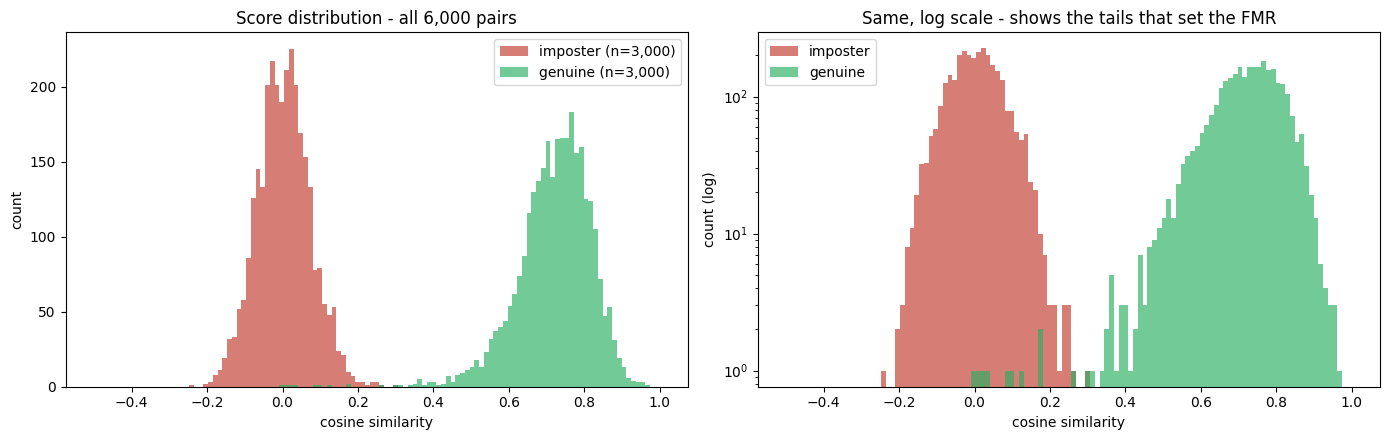

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
bins = np.linspace(-0.5, 1.0, 120)
ax.hist(imp_scores, bins=bins, alpha=0.65, color="#c0392b", label=f"imposter (n={len(imp_scores):,})")
ax.hist(gen_scores, bins=bins, alpha=0.65, color="#27ae60", label=f"genuine (n={len(gen_scores):,})")
ax.set_xlabel("cosine similarity"); ax.set_ylabel("count")
ax.set_title(f"Score distribution - all {N_PAIRS:,} pairs")
ax.legend()

ax = axes[1]
ax.hist(imp_scores, bins=bins, alpha=0.65, color="#c0392b", label="imposter")
ax.hist(gen_scores, bins=bins, alpha=0.65, color="#27ae60", label="genuine")
ax.set_yscale("log")
ax.set_xlabel("cosine similarity"); ax.set_ylabel("count (log)")
ax.set_title("Same, log scale - shows the tails that set the FMR")
ax.legend()

plt.tight_layout(); save_fig("06_score_distributions.png"); plt.show()

## Step 5 - the decision threshold

Two standard criteria, both computed on LFW as the supervisor suggested:

* **EER** - the threshold where FMR equals FNMR. One number, no free parameters. Used
  as the **headline operating point** in notebooks 08 and 09. (The reference xSSAB
  implementation also picks its threshold by EER.)
* **FMR targets** - the threshold at which at most 1 in 10 / 100 / 1000 imposter pairs
  is accepted. Closer to how a deployed system is configured, and reported alongside
  every attack result as a sensitivity check.

A caveat worth stating: with 3,000 imposter pairs, FMR = 10^-3 is resolved by **3
pairs**, so that row is a coarse estimate. FMR = 10^-2 (30 pairs) is the tightest
operating point this dataset supports comfortably.

In [11]:
tau_eer, eer = compute_eer(gen_sorted, imp_sorted)

operating_points = {"EER": tau_eer}
for target in FMR_TARGETS:
    operating_points[f"FMR<={target:g}"] = threshold_at_fmr(imp_sorted, target)
operating_points[f"legacy ({LEGACY_THRESHOLD})"] = LEGACY_THRESHOLD

print(f"Equal Error Rate : {eer * 100:.3f}%   at threshold {tau_eer:.4f}")
print()
print(f"{'operating point':>18}  {'threshold':>9}  {'FMR':>8}  {'FNMR':>8}  {'accuracy':>9}")
print("-" * 62)
op_rows = []
for name, t in operating_points.items():
    fmr, fnmr, acc = operating_point(scores, IS_GENUINE, t)
    op_rows.append(dict(operating_point=name, threshold=t, fmr=fmr, fnmr=fnmr, accuracy=acc))
    print(f"{name:>18}  {t:>9.4f}  {fmr:>8.4%}  {fnmr:>8.4%}  {acc:>9.4%}")
op_df = pd.DataFrame(op_rows)

Equal Error Rate : 0.300%   at threshold 0.2136

   operating point  threshold       FMR      FNMR   accuracy
--------------------------------------------------------------
               EER     0.2136   0.3000%   0.3000%   99.7000%
          FMR<=0.1     0.0943  10.0000%   0.1667%   94.9167%
         FMR<=0.01     0.1683   1.0000%   0.2667%   99.3667%
        FMR<=0.001     0.2483   0.1000%   0.3000%   99.8000%
      legacy (0.3)     0.3000   0.0333%   0.3333%   99.8167%


### What 0.30 actually was

The row above for the legacy threshold is the honest answer to "the threshold seems to
be set randomly at 0.3". Read off its FMR: that is the false match rate notebooks 01-05
were implicitly operating at. It is not absurd - the two distributions are very well
separated on LFW, so a wide range of thresholds gives high accuracy - but it was never
*chosen*, and the exact figure matters as soon as an attack is asked to push a score
across it.

## Step 6 - DET curve and the error trade-off

The left panel is the standard DET curve (FNMR against FMR, log-log): the closer to the
origin, the better the system. The EER is where it crosses the diagonal. The right panel
shows both error rates as a function of the threshold, which is the more useful view for
this project - it shows how much room an attack has to move a score before the decision
changes.

saved /kaggle/working/06_det_and_errors.png


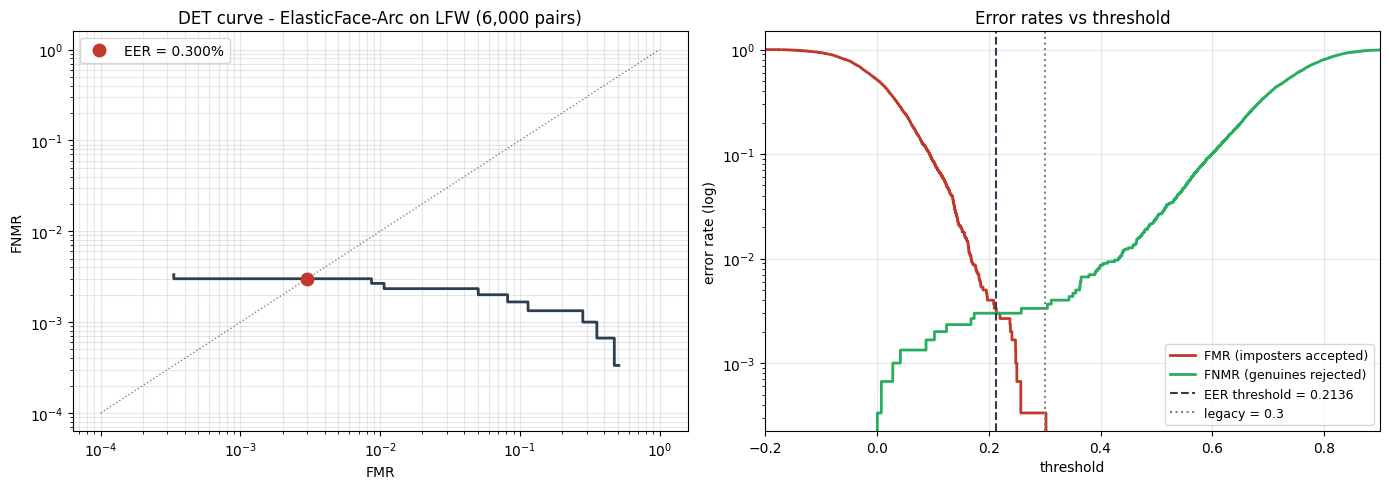

In [12]:
cand = candidate_thresholds(gen_sorted, imp_sorted)
fmr_curve = fmr_at(imp_sorted, cand)
fnmr_curve = fnmr_at(gen_sorted, cand)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ok = (fmr_curve > 0) & (fnmr_curve > 0)
ax.plot(fmr_curve[ok], fnmr_curve[ok], color="#2c3e50", lw=2)
ax.plot([1e-4, 1], [1e-4, 1], ls=":", color="grey", lw=1)
ax.plot(eer, eer, "o", color="#c0392b", ms=9, label=f"EER = {eer:.3%}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("FMR"); ax.set_ylabel("FNMR")
ax.set_title("DET curve - ElasticFace-Arc on LFW (6,000 pairs)")
ax.legend(); ax.grid(alpha=0.3, which="both")

ax = axes[1]
ax.plot(cand, fmr_curve, color="#c0392b", lw=2, label="FMR (imposters accepted)")
ax.plot(cand, fnmr_curve, color="#27ae60", lw=2, label="FNMR (genuines rejected)")
ax.axvline(tau_eer, color="#2c3e50", ls="--", lw=1.5, label=f"EER threshold = {tau_eer:.4f}")
ax.axvline(LEGACY_THRESHOLD, color="grey", ls=":", lw=1.5, label=f"legacy = {LEGACY_THRESHOLD}")
ax.set_yscale("log"); ax.set_xlim(-0.2, 0.9)
ax.set_xlabel("threshold"); ax.set_ylabel("error rate (log)")
ax.set_title("Error rates vs threshold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout(); save_fig("06_det_and_errors.png"); plt.show()

## Step 7 - the LFW 10-fold protocol

The standard way LFW accuracy is reported, and the reason the 6,000 pairs are grouped
into folds at all: for each fold, the threshold is chosen on the **other nine** folds
and applied to the held-out one. That makes the accuracy an out-of-sample number rather
than a best-case fit.

This is also the strongest end-to-end sanity check available: if the result lands near
the accuracy published for ElasticFace-Arc, then the weights, the preprocessing and the
pair layout are all correct simultaneously.

In [13]:
fold_results = []
for f in range(N_FOLDS):
    test = FOLD == f
    train = ~test

    g_tr = np.sort(scores[train & IS_GENUINE])
    i_tr = np.sort(scores[train & ~IS_GENUINE])
    c = candidate_thresholds(g_tr, i_tr)
    # accuracy on the 9 training folds, evaluated at every candidate threshold
    n_tr = len(g_tr) + len(i_tr)
    acc_tr = ((1 - fnmr_at(g_tr, c)) * len(g_tr) + (1 - fmr_at(i_tr, c)) * len(i_tr)) / n_tr
    t_star = float(c[int(np.argmax(acc_tr))])

    _, _, acc_te = operating_point(scores[test], IS_GENUINE[test], t_star)
    fold_results.append(dict(fold=f, threshold=t_star,
                             train_accuracy=float(acc_tr.max()), test_accuracy=acc_te))

fold_acc_df = pd.DataFrame(fold_results)
print(fold_acc_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

mean_acc = fold_acc_df.test_accuracy.mean()
std_acc = fold_acc_df.test_accuracy.std()
mean_thr = fold_acc_df.threshold.mean()
print()
print(f"LFW 10-fold accuracy : {mean_acc:.4%} +/- {std_acc:.4%}")
print(f"mean fold threshold  : {mean_thr:.4f}   (global EER threshold: {tau_eer:.4f})")

 fold  threshold  train_accuracy  test_accuracy
    0     0.3024          0.9989         0.9933
    1     0.2574          0.9981         1.0000
    2     0.2574          0.9981         1.0000
    3     0.2574          0.9983         0.9983
    4     0.2574          0.9987         0.9950
    5     0.2503          0.9983         0.9967
    6     0.2574          0.9985         0.9967
    7     0.2574          0.9981         1.0000
    8     0.2574          0.9981         1.0000
    9     0.2574          0.9981         1.0000

LFW 10-fold accuracy : 99.8000% +/- 0.2460%
mean fold threshold  : 0.2612   (global EER threshold: 0.2136)


## Step 8 - save the protocol

`thresholds.json` is the contract between this notebook and the rest of the series.
Notebooks 08 and 09 recompute the scores themselves (it costs under a minute) and will
arrive at the same numbers, so the file is for the write-up and for notebook 10 rather
than a hard dependency.

In [14]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

thresholds = {
    "eer_threshold": tau_eer,
    "eer": eer,
    "fmr_thresholds": {f"{t:g}": threshold_at_fmr(imp_sorted, t) for t in FMR_TARGETS},
    "legacy_threshold": LEGACY_THRESHOLD,
    "lfw_10fold_accuracy_mean": float(mean_acc),
    "lfw_10fold_accuracy_std": float(std_acc),
    "lfw_10fold_mean_threshold": float(mean_thr),
    "n_pairs": int(N_PAIRS),
    "n_genuine": int(IS_GENUINE.sum()),
    "n_imposter": int((~IS_GENUINE).sum()),
    "probe_side": PROBE_SIDE,
    "probe_seed": PROBE_SEED,
}
with open(os.path.join(OUTPUT_DIR, "thresholds.json"), "w") as fh:
    json.dump(thresholds, fh, indent=2)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "protocol_scores.npz"),
    scores=scores, is_genuine=IS_GENUINE, fold=FOLD,
    probe_img=PROBE_IMG, ref_img=REF_IMG, embeddings=emb,
)
op_df.to_csv(os.path.join(OUTPUT_DIR, "operating_points.csv"), index=False)
fold_acc_df.to_csv(os.path.join(OUTPUT_DIR, "fold_accuracy.csv"), index=False)
fold_df.to_csv(os.path.join(OUTPUT_DIR, "fold_separation.csv"), index=False)

print("saved:")
for f in ["thresholds.json", "protocol_scores.npz", "operating_points.csv",
          "fold_accuracy.csv", "fold_separation.csv"]:
    print("  ", f)
print(json.dumps(thresholds, indent=2))

saved:
   thresholds.json
   protocol_scores.npz
   operating_points.csv
   fold_accuracy.csv
   fold_separation.csv
{
  "eer_threshold": 0.21356485784053802,
  "eer": 0.0030000000000000014,
  "fmr_thresholds": {
    "0.1": 0.09425855427980423,
    "0.01": 0.1682628095149994,
    "0.001": 0.24828895926475525
  },
  "legacy_threshold": 0.3,
  "lfw_10fold_accuracy_mean": 0.998,
  "lfw_10fold_accuracy_std": 0.0024595492912420783,
  "lfw_10fold_mean_threshold": 0.2611784994602203,
  "n_pairs": 6000,
  "n_genuine": 3000,
  "n_imposter": 3000,
  "probe_side": "random",
  "probe_seed": 20260728
}


## Results and discussion

**The dataset.** All 12,000 images are present and pair up into 6,000 pairs (3,000
genuine, 3,000 imposter). The assumed LFW view-2 layout - alternating blocks of 300
genuine and 300 imposter pairs - is confirmed decisively: it produces a mean score gap of
**+0.7165 (Cohen's d = 8.32)**, while both competing hypotheses collapse to d ~ 0.01, and
the separation holds in **all 10 folds** independently (per-fold gaps 0.704 to 0.728,
genuine/imposter overlap at most 0.4%). Notebooks 01-05 used 900 of these pairs - 15% of
the data, at a 2:1 genuine:imposter ratio rather than the balanced 1:1 of the real
protocol. That imbalance is why the imposter tail was previously too thin to estimate a
false match rate from at all.

**The model is correctly reproduced.** LFW 10-fold accuracy is **99.80% +/- 0.25%**, which
matches the figure published for ElasticFace-Arc. Since that number only comes out right if
the weights, the preprocessing *and* the pair labelling are all correct simultaneously, it
is the check that licenses everything downstream. Genuine scores average +0.720 (sd 0.099)
against +0.003 (sd 0.071) for imposters.

**The threshold.** The EER is **0.300% at a threshold of 0.2136**. Thresholds at target
false match rates are 0.0943 (FMR 10%), 0.1683 (FMR 1%) and 0.2483 (FMR 0.1%).

**An honest note on the old 0.30.** Read off the table: 0.30 corresponds to an FMR of
0.033% - one imposter pair in 3,000 - and yields 99.82% accuracy, in fact the highest in
the table. So the hand-picked value was not harmful; it sat close to the accuracy-optimal
operating point, and the fold-wise thresholds fitted by the LFW protocol cluster at
0.257-0.302 around it. The objection was methodological rather than empirical: the value
was never *derived*, so nothing could be said about where on the error trade-off it sat,
and "the attack pushed the score across the threshold" was a claim about an unspecified
operating point. That is now fixed, and it is worth stating plainly that fixing it does not
overturn any earlier result.

**Consequences for the attack notebooks.** 2,991 of the 3,000 genuine pairs are accepted at
the EER threshold and form the attack set for notebook 09; the count is essentially
invariant to the threshold choice (2,990-2,995 across every operating point in the table),
so no conclusion there can hinge on it. Nine genuine pairs are rejected - scores from 0.001
to 0.174, i.e. hard poses or LFW label noise - and nine imposter pairs are accepted; both
groups are excluded from the corresponding attack, since flipping a decision that was
already wrong is not an attack success. Only **one** pair in the attack set sits within
`SIM_TOL` of the threshold, so the two-sided score constraint in notebook 09 has ample room
on essentially every pair.

**Limitations.** LFW is close to saturated for a model of this quality: the whole error
budget is 9 pairs on each side, so the tail estimates rest on very few events. FMR = 10^-3
is resolved by exactly 3 imposter pairs and should be read as indicative; FMR = 10^-2 (30
pairs) is the tightest operating point this dataset supports comfortably. A harder
benchmark such as IJB-C would give a more discriminating operating curve, but LFW is the
dataset provided for this project and the one the supervisor asked us to calibrate on.

**Next.** Notebook 07 evaluates whether the explanation methods are faithful in the first
place, using insertion and deletion curves over these same 6,000 pairs.
